In [1]:
import polars as pl
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
counter_id = 100034894
counters = pl.read_csv("../../data/counters_hourly.csv", try_parse_dates=True).filter(pl.col("counter_site_id") == counter_id)

<Axes: xlabel='datetime', ylabel='channels_all'>

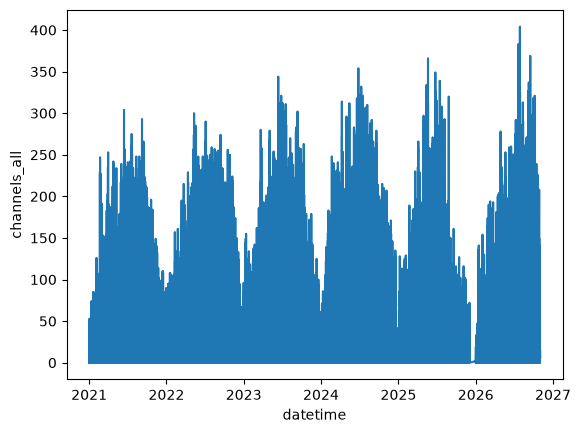

In [3]:
sns.lineplot(x=counters["datetime"], y=counters["channels_all"])

In [4]:
from sklearn.model_selection import train_test_split

features = counters.select(
        pl.col("site_temperature"),
        pl.col("site_rain_accumulation"),
        pl.col("datetime").dt.hour().alias("hour"),
        pl.col("datetime").dt.weekday().alias("weekday"),
        pl.col("datetime").dt.month().alias("month"),
        pl.col("datetime").dt.year().alias("year"),
    )
target = counters["channels_all"]

features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.1, random_state=67)

In [5]:
def date_features(df):
    return df.select(
        pl.col("site_temperature"),
        pl.col("site_rain_accumulation"),
        pl.col("datetime").dt.hour().alias("hour"),
        pl.col("datetime").dt.weekday().alias("weekday"),
        pl.col("datetime").dt.month().alias("month"),
        pl.col("datetime").dt.year().alias("year"),
    )

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import StandardScaler

baseline = make_pipeline(
    StandardScaler(),
    PoissonRegressor()
)

X_train = features_train
baseline.fit(X_train, target_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('poissonregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['site_temperature','site_rain_accumulation','hour','weekday','month', 'year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [7]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_poisson_deviance, r2_score

scores = [root_mean_squared_error, mean_absolute_error, mean_poisson_deviance, r2_score]


median_prediction = target_test*0 + target_train.mean()
print([score(target_test, median_prediction) for score in scores])

[54.69991385745951, 42.075964662505946, 56.701367208384184, -0.0004064328214652413]


In [8]:
baseline_pred_test = baseline.predict(features_test)
print([score(target_test, baseline_pred_test) for score in scores])

[48.42207946115076, 34.937247826435275, 42.21981265477713, 0.21604693393612573]


In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor

gbd = HistGradientBoostingRegressor(loss="poisson")

X_train = features_train
gbd.fit(X_train, target_train)

,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'poisson'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide <categorical_support_gbdt>` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`

## Partial dependence of the HGBD model

Thin blue lines are ICE curves (one per sampled test row), the orange line is their average (the partial dependence).

In [10]:
from sklearn.inspection import PartialDependenceDisplay

# PartialDependenceDisplay can't read polars frames or integer columns, so give it a float pandas copy
X_pdp = features_test.cast(pl.Float64).to_pandas()

def plot_dependence(feature):
    fig, ax = plt.subplots(figsize=(8, 4))
    PartialDependenceDisplay.from_estimator(
        gbd, X_pdp, [feature],
        kind="both", subsample=300, random_state=0,
        ice_lines_kw={"alpha": 0.1},
        pd_line_kw={"color": "tab:orange", "lw": 3},
        ax=ax,
    )
    plt.show()

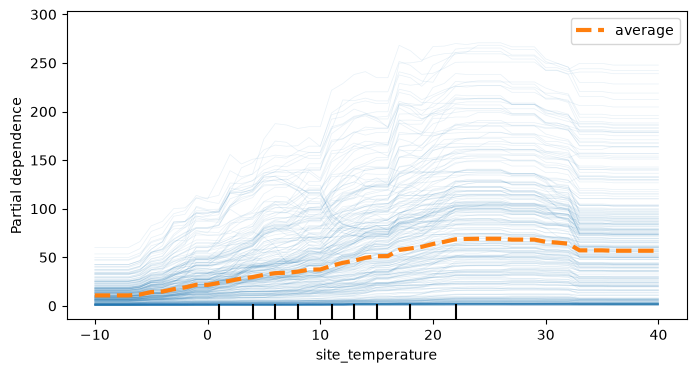

In [11]:
plot_dependence("site_temperature")

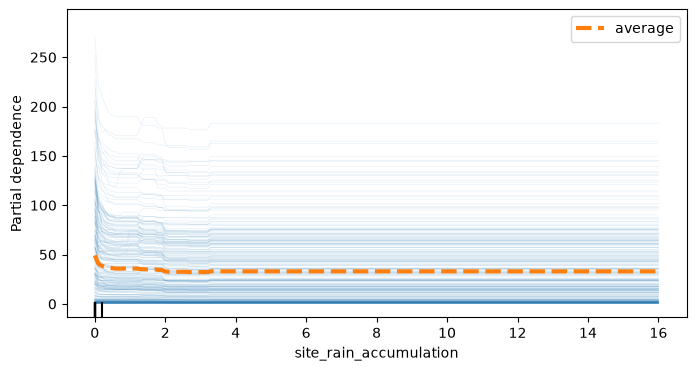

In [12]:
plot_dependence("site_rain_accumulation")

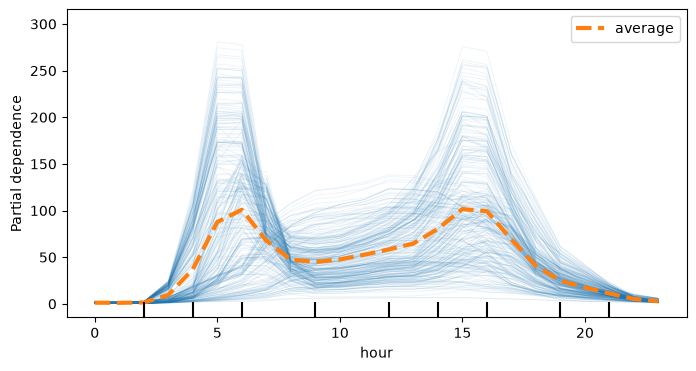

In [13]:
plot_dependence("hour")

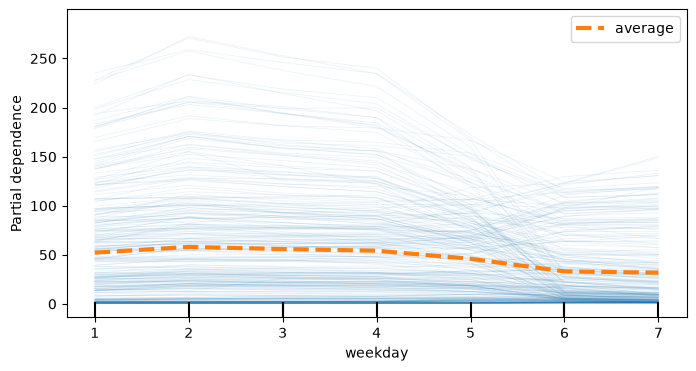

In [14]:
plot_dependence("weekday")

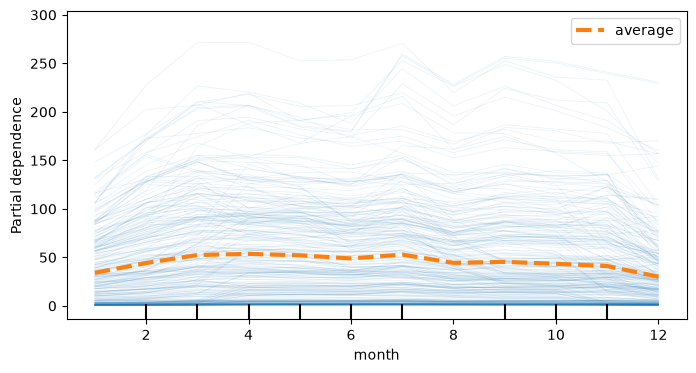

In [15]:
plot_dependence("month")

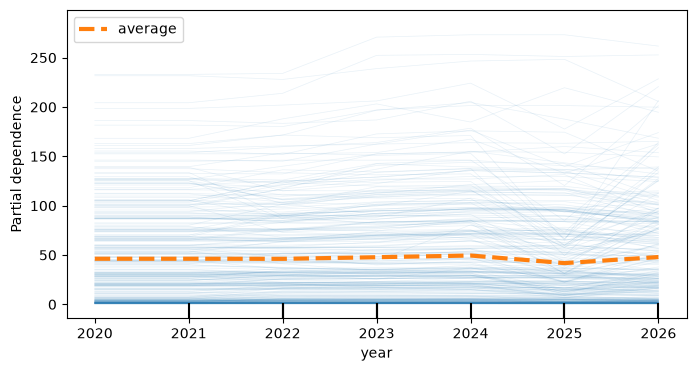

In [16]:
plot_dependence("year")